# 01 · Identifying SV candidates at GWAS loci

*Prepared by Junyoung Park ([jpark01@stanford.edu](mailto:jpark01@stanford.edu)). Analysis code adapted from [tjense25/ADRC-Flagship-lrGS-Code](https://github.com/tjense25/ADRC-Flagship-lrGS-Code) by Tanner D. Jensen (MIT License).*

Given a GWAS locus, which structural variants (SVs) are nearby, how
common are they, and how well are they tagged by SNVs?

1. Look at the GWAS signal and its lead SNV.
2. List the SVs near the lead SNV with their type, length and allele frequency.
3. Measure linkage disequilibrium (LD, r²) between each SV and the GWAS lead SNV.
   The paper calls an SV **high-tagging** when r² ≥ 0.6 with a GWAS lead SNV.
4. Find the best-tagging SNV of an SV.
5. Case study: an SV that SNVs tag poorly (HP).

The genotypes come from the SPHERE Twin of the Stanford ADRC/SAMS long-read cohort: SVs for 544 people
from nanopore genomes and SNVs/indels for 416 of them from short-read genomes. Twin genotypes are
continuous dosages.

In [1]:
# On Google Colab (Runtime > Change runtime type > R) this first downloads the workshop files.
if (!file.exists("../R/setup.R") && !file.exists("R/setup.R")) {
    if (!dir.exists("sv-finemapping-coloc-tutorial"))
        system("git clone --depth 1 https://github.com/Junkkkk/sv-finemapping-coloc-tutorial.git")
    if (!dir.exists("sv-finemapping-coloc-tutorial/notebooks"))
        stop("Could not download the workshop files from GitHub. Check the internet connection.")
    setwd("sv-finemapping-coloc-tutorial/notebooks")
}
source(if (file.exists("../R/setup.R")) "../R/setup.R" else "R/setup.R")
LOCI

locus,chrom,region_start,region_end,layer,pheno_id,label,sv_id,gwas,gwas_lead_pos
<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>
HP,chr16,71054505,73058850,Plasma,ENSG00000257017:HP.3054.3.2,"HP protein (plasma, aptamer 3054-3)",Sniffles2.DEL.14B0MF,,NA
HP,chr16,71054505,73058850,Plasma,ENSG00000257017:HP.7905.30.3,"HP protein (plasma, aptamer 7905-30)",Sniffles2.DEL.14B0MF,,NA
HP,chr16,71054505,73058850,CSF,HP.3054.3.2:ENSG00000257017:HP,"HP protein (CSF, aptamer 3054-3)",Sniffles2.DEL.14B0MF,,NA
HP,chr16,71054505,73058850,CSF,HP.7905.30.3:ENSG00000257017:HP,"HP protein (CSF, aptamer 7905-30)",Sniffles2.DEL.14B0MF,,NA
COG7,chr16,22462828,24505148,Methylation,chr16_10_113,Methylation segment near GGA2/COG7,Sniffles2.DEL.8FEMF,AD,23466676
MAPT,chr17,44915490,47511509,RNA,ENSG00000238083:LRRC37A2,LRRC37A2 expression (PBMC),Sniffles2.INS.1142M10,AD,46613342
MAPT,chr17,44915490,47511509,RNA,ENSG00000238083:LRRC37A2,LRRC37A2 expression (PBMC),Sniffles2.INS.1142M10,AD,46720553
MAPT,chr17,44915490,47511509,RNA,ENSG00000238083:LRRC37A2,LRRC37A2 expression (PBMC),Sniffles2.INS.1142M10,PD,46276519
MAPT,chr17,44915490,47511509,RNA,ENSG00000238083:LRRC37A2,LRRC37A2 expression (PBMC),Sniffles2.INS.1142M10,PD,46783637


In [2]:
geno <- lapply(setNames(unique(LOCI$locus), unique(LOCI$locus)), function(l) list(
    SV = read_genotypes(file.path(DATA_DIR, "genotypes", paste0(l, ".SV.tsv.gz"))),
    SNV = read_genotypes(file.path(DATA_DIR, "genotypes", paste0(l, ".SNV.tsv.gz")))))
read_gwas <- function(gwas, locus) fread(file.path(DATA_DIR, "gwas", paste0(gwas, ".", locus, ".tsv.gz")))

# GWAS leads tested in the paper
leads <- unique(LOCI[gwas != "", .(locus, chrom, gwas, lead = as.integer(gwas_lead_pos))])
leads

locus,chrom,gwas,lead
<chr>,<chr>,<chr>,<int>
COG7,chr16,AD,23466676
MAPT,chr17,AD,46613342
MAPT,chr17,AD,46720553
MAPT,chr17,PD,46276519
MAPT,chr17,PD,46783637


## 1. The GWAS signal

GWAS files are on GRCh38 and keep variants with effect-allele frequency between 0.02 and 0.98.
AD: Bellenguez et al. 2022. PD: Kim et al. 2024.

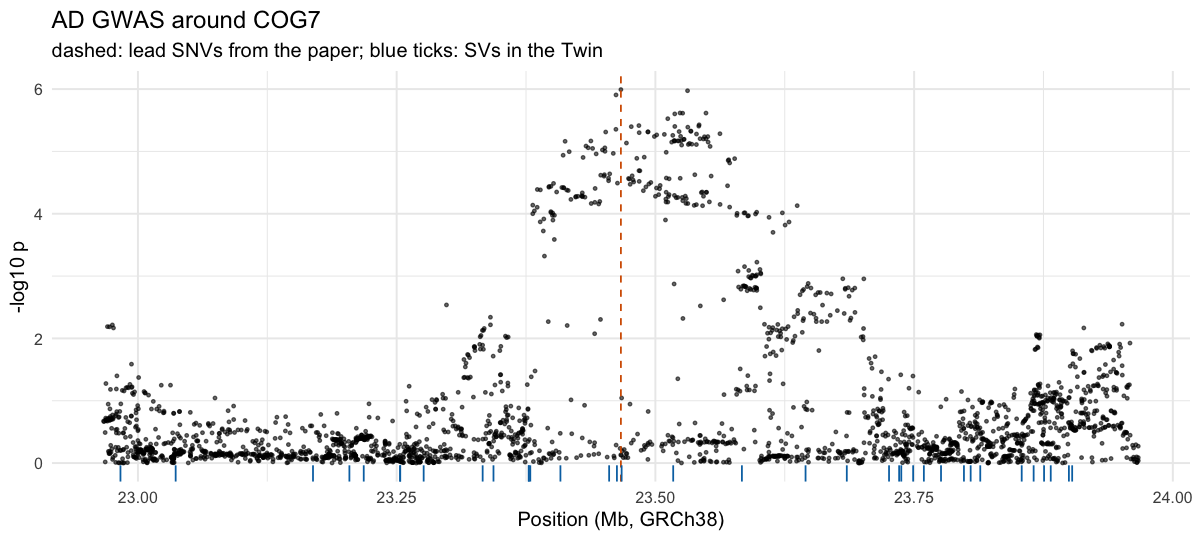

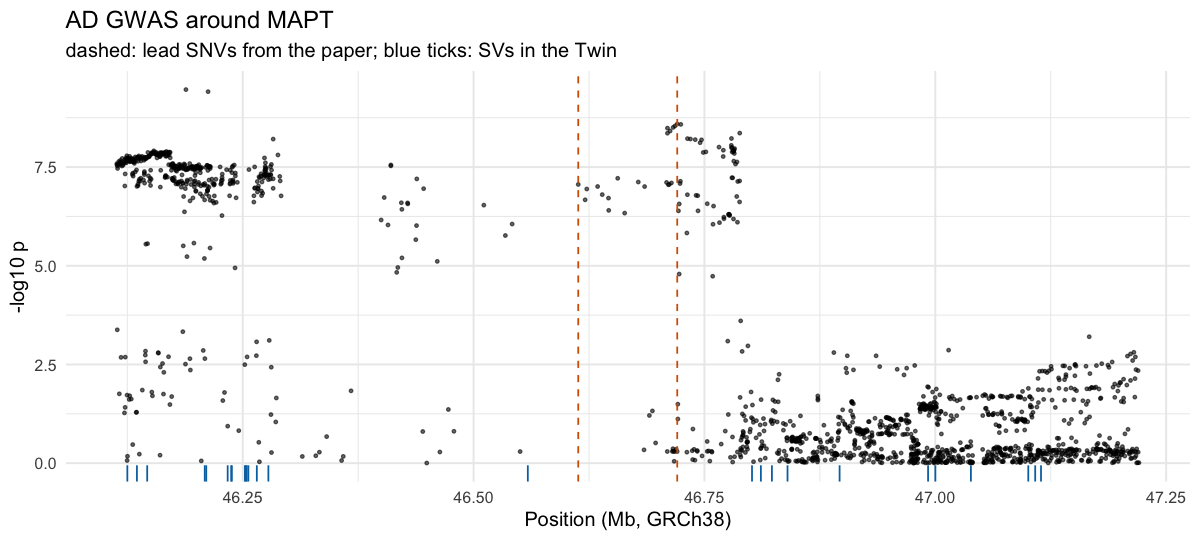

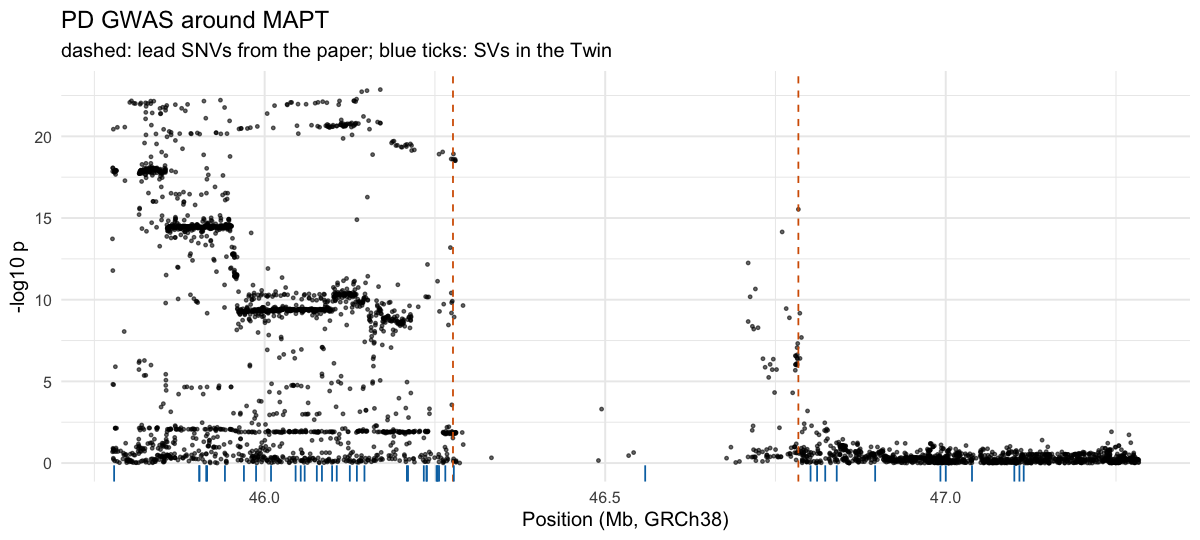

In [3]:
plot_gwas <- function(gwas, locus, lead_positions, half_window = 5e5) {
    g <- read_gwas(gwas, locus)
    lo <- min(lead_positions) - half_window; hi <- max(lead_positions) + half_window
    g <- g[snp_pos >= lo & snp_pos <= hi]
    sv <- geno[[locus]]$SV$info[start >= lo & start <= hi]
    ggplot(g, aes(snp_pos / 1e6, -log10(pvalue))) +
        geom_point(size = 0.7, alpha = 0.6) +
        geom_vline(xintercept = lead_positions / 1e6, linetype = 2, colour = "#D55E00") +
        geom_rug(data = sv, aes(x = start / 1e6), inherit.aes = FALSE, colour = "#0072B2", length = unit(0.04, "npc")) +
        labs(title = sprintf("%s GWAS around %s", gwas, locus),
             subtitle = "dashed: lead SNVs from the paper; blue ticks: SVs in the Twin",
             x = "Position (Mb, GRCh38)", y = "-log10 p")
}
plot_gwas("AD", "COG7", leads[locus == "COG7", lead])
plot_gwas("AD", "MAPT", leads[locus == "MAPT" & gwas == "AD", lead])
plot_gwas("PD", "MAPT", leads[locus == "MAPT" & gwas == "PD", lead])

The MAPT region carries several AD and PD leads. It sits on a ~1 Mb inversion haplotype (H1/H2)
with very long-range LD, which will matter for fine-mapping later.

## 2. SVs near a GWAS lead

For each lead we list SVs within ±100 kb. `distance_kb` is 0 when the SV spans the lead. Allele frequency (AF) is computed from
the Twin dosages, so it is approximate.

A few calls in the MAPT region span hundreds of kb or more; they reflect the complex structure of the
MAPT inversion region rather than simple deletions.

In [4]:
sv_af <- function(locus) {
    sv <- geno[[locus]]$SV
    data.table(sv$info, AF = rowSums(sv$mat) / (2 * ncol(sv$mat)))
}
svs_near <- function(locus, lead, half_window = 1e5) {
    s <- sv_af(locus)[start <= lead + half_window & end >= lead - half_window]
    s[, .(variant_id, type = sub("Sniffles2\\.(\\w+)\\..*", "\\1", variant_id), start, end,
          length_bp = abs(svlen),
          distance_kb = round(ifelse(start <= lead & end >= lead, 0, ifelse(end < lead, end - lead, start - lead)) / 1e3, 1),
          AF = round(AF, 3))]
}
for (i in seq_len(nrow(leads))) {
    cat(sprintf("\n%s lead %s:%d\n", leads$gwas[i], leads$chrom[i], leads$lead[i]))
    print(svs_near(leads$locus[i], leads$lead[i]))
}


AD lead chr16:23466676
            variant_id type    start      end length_bp distance_kb    AF
1: Sniffles2.INS.8EDMF  INS 23377587 23377587        45       -89.1 0.236
2: Sniffles2.DEL.8F7MF  DEL 23377752 23377791        39       -88.9 0.201
3: Sniffles2.INS.8EEMF  INS 23379122 23379122        91       -87.6 0.051
4: Sniffles2.INS.8F9MF  INS 23408242 23408242        34       -58.4 0.025
5: Sniffles2.INS.8FAMF  INS 23455313 23455313       734       -11.4 0.138
6: Sniffles2.DEL.8FEMF  DEL 23462828 23463036       208        -3.6 0.202
7: Sniffles2.INS.8FBMF  INS 23467388 23467388        31         0.7 0.023
8: Sniffles2.DEL.905MF  DEL 23517222 23517535       313        50.5 0.829

AD lead chr17:46613342
              variant_id type    start      end length_bp distance_kb    AF
1: Sniffles2.DEL.1128M10  DEL 45585855 67950567  22364712         0.0 0.089
2: Sniffles2.DEL.117FM10  DEL 46558734 46558814        80       -54.5 0.131

AD lead chr17:46720553
              variant_id type    s

## 3. LD between SVs and the GWAS lead SNV

r² is the squared Pearson correlation of genotype dosages across the 416 people who have both SV and
SNV genotypes. One AD lead (chr17:46,613,342) is not in our SNV panel, so the code uses the most
significant GWAS SNV within 100 kb that is in the panel instead.

In [5]:
people <- function(locus) intersect(colnames(geno[[locus]]$SV$mat), colnames(geno[[locus]]$SNV$mat))

lead_in_panel <- function(gwas, locus, lead, half_window = 1e5) {
    snv <- geno[[locus]]$SNV$info
    hit <- snv[pos == lead]
    if (nrow(hit) > 0) return(list(id = hit$variant_id[1], proxy = FALSE))
    g <- read_gwas(gwas, locus)[abs(snp_pos - lead) <= half_window & snp_pos %in% snv$pos][order(pvalue)]
    list(id = snv[pos == g$snp_pos[1]]$variant_id[1], proxy = TRUE)
}

sv_lead_ld <- function(gwas, locus, lead, half_window = 1e5) {
    ids <- people(locus)
    l <- lead_in_panel(gwas, locus, lead)
    lead_gt <- geno[[locus]]$SNV$mat[l$id, ids]
    near <- svs_near(locus, lead, half_window)
    near[, r2_with_lead := round(sapply(variant_id, function(v) cor(geno[[locus]]$SV$mat[v, ids], lead_gt)^2), 3)]
    near[, high_tagging := r2_with_lead >= 0.6]
    cat(sprintf("\n%s lead %s:%d -> SNV used: %s%s\n", gwas, unique(LOCI$chrom[LOCI$locus == locus]), lead, l$id,
                if (l$proxy) " (proxy: lead not in panel)" else ""))
    near[order(-r2_with_lead)]
}
for (i in seq_len(nrow(leads))) print(sv_lead_ld(leads$gwas[i], leads$locus[i], leads$lead[i]))


AD lead chr16:23466676 -> SNV used: 16:23466676:C:CCA
            variant_id type    start      end length_bp distance_kb    AF r2_with_lead high_tagging
1: Sniffles2.DEL.8FEMF  DEL 23462828 23463036       208        -3.6 0.202        0.710         TRUE
2: Sniffles2.DEL.905MF  DEL 23517222 23517535       313        50.5 0.829        0.620         TRUE
3: Sniffles2.INS.8FAMF  INS 23455313 23455313       734       -11.4 0.138        0.446        FALSE
4: Sniffles2.INS.8FBMF  INS 23467388 23467388        31         0.7 0.023        0.075        FALSE
5: Sniffles2.INS.8EDMF  INS 23377587 23377587        45       -89.1 0.236        0.027        FALSE
6: Sniffles2.INS.8F9MF  INS 23408242 23408242        34       -58.4 0.025        0.021        FALSE
7: Sniffles2.DEL.8F7MF  DEL 23377752 23377791        39       -88.9 0.201        0.001        FALSE
8: Sniffles2.INS.8EEMF  INS 23379122 23379122        91       -87.6 0.051        0.001        FALSE

AD lead chr17:46613342 -> SNV used: 17:46709

## 4. Best-tagging SNV of an SV

Consider SNVs within 1 Mb of the SV with minor allele
frequency > 0.01 and < 50% missing genotypes; the best tag is the SNV with the highest r².
We do this for the three SVs highlighted in the paper.

In [6]:
best_tag <- function(locus, sv_id) {
    ids <- people(locus)
    sv <- geno[[locus]]$SV; snv <- geno[[locus]]$SNV
    s <- sv$info[variant_id == sv_id]
    in_window <- snv$info$pos >= s$start - 1e6 & snv$info$pos <= s$end + 1e6
    m <- snv$mat[in_window, ids]
    maf <- rowSums(m, na.rm = TRUE) / (2 * ncol(m)); maf <- pmin(maf, 1 - maf)
    m <- m[maf > .01 & rowMeans(is.na(m)) < .5, ]
    r2 <- apply(m, 1, function(x) cor(sv$mat[sv_id, ids], x, use = "complete.obs")^2)
    top <- order(-r2)[1:5]
    data.table(SV = sv_id, SNV = names(r2)[top], r2 = round(r2[top], 3),
               distance_kb = round((snv$info[match(names(r2)[top], variant_id)]$pos - s$start) / 1e3, 1))
}
paper_svs <- unique(LOCI[, .(locus, sv_id)])
for (i in seq_len(nrow(paper_svs))) print(best_tag(paper_svs$locus[i], paper_svs$sv_id[i]))

                     SV             SNV    r2 distance_kb
1: Sniffles2.DEL.14B0MF 16:72072066:C:T 0.324        14.9
2: Sniffles2.DEL.14B0MF 16:72045758:T:C 0.322       -11.4
3: Sniffles2.DEL.14B0MF 16:72080103:T:C 0.321        23.0
4: Sniffles2.DEL.14B0MF 16:72110275:C:T 0.189        53.1
5: Sniffles2.DEL.14B0MF 16:72120610:T:C 0.177        63.5
                    SV             SNV    r2 distance_kb
1: Sniffles2.DEL.8FEMF 16:23450734:A:G 0.892       -12.1
2: Sniffles2.DEL.8FEMF 16:23450433:C:A 0.885       -12.4
3: Sniffles2.DEL.8FEMF 16:23455860:C:T 0.885        -7.0
4: Sniffles2.DEL.8FEMF 16:23459318:G:A 0.885        -3.5
5: Sniffles2.DEL.8FEMF 16:23474032:G:C 0.885        11.2
                      SV              SNV    r2 distance_kb
1: Sniffles2.INS.1142M10 17:45636813:CT:C 0.919      -278.7
2: Sniffles2.INS.1142M10  17:45607655:T:C 0.909      -307.8
3: Sniffles2.INS.1142M10  17:45772290:A:C 0.908      -143.2
4: Sniffles2.INS.1142M10  17:45841702:T:G 0.908       -73.8
5: Sniffle

## 5. Case study: the HP deletion

The paper describes a 1.7 kb deletion in *HP* that spans two exons, changes the protein isoform, and is
poorly captured by short-read data. Its best-tagging SNV in the paper's Figure 5d is **rs217181**
(chr16:72,080,103). Does the SV or the SNV explain HP protein levels better?

We fit the QTL model of notebook 02 (same covariates) for the deletion and
for rs217181, in the same people.

In [7]:
csf <- fread(file.path(DATA_DIR, "phenotypes", "CSF.phenotypes.tsv"))
cv <- fread(file.path(DATA_DIR, "covariates", "CSF.covariates.tsv.gz"))
covars <- as.matrix(cv[, -1], rownames.value = cv$ID)[, 1:(14 + 30)]
hp <- unlist(csf[pheno_id == "HP.3054.3.2:ENSG00000257017:HP", -(1:4)])
ids <- intersect(names(hp), intersect(colnames(geno$HP$SV$mat), colnames(geno$HP$SNV$mat)))

assoc <- function(gt) {
    X <- cbind(GT = gt, covars[ids, ])
    f <- fastLmPure(X, hp[ids])
    c(beta = f$coefficients[1], p = pt(abs(f$coefficients[1] / f$se[1]), df = nrow(X) - ncol(X), lower.tail = FALSE))
}
rs217181 <- geno$HP$SNV$info[pos == 72080103]$variant_id
rbind(`1.7 kb deletion (Sniffles2.DEL.14B0MF)` = assoc(geno$HP$SV$mat["Sniffles2.DEL.14B0MF", ids]),
      `rs217181` = assoc(geno$HP$SNV$mat[rs217181, ids]))
cat("people:", length(ids), "  r2 between the deletion and rs217181 in these people:",
    round(cor(geno$HP$SV$mat["Sniffles2.DEL.14B0MF", ids], geno$HP$SNV$mat[rs217181, ids])^2, 3), "\n")

,beta.GT,p.GT
1.7 kb deletion (Sniffles2.DEL.14B0MF),0.8335749,1.120238e-30
rs217181,0.7455451,9.684916e-16


people: 183   r2 between the deletion and rs217181 in these people: 0.363 


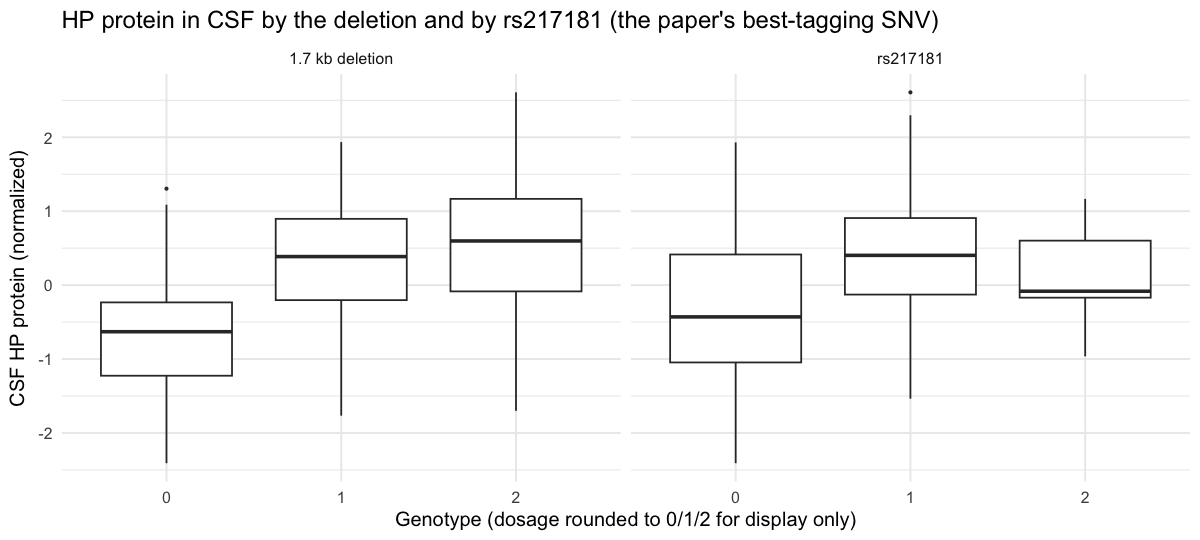

In [8]:
to_012 <- function(x) pmin(pmax(round(x), 0), 2)
d <- rbind(data.table(variant = "1.7 kb deletion", genotype = to_012(geno$HP$SV$mat["Sniffles2.DEL.14B0MF", ids]), HP = hp[ids]),
           data.table(variant = "rs217181", genotype = to_012(geno$HP$SNV$mat[rs217181, ids]), HP = hp[ids]))
ggplot(d, aes(factor(genotype), HP)) + geom_boxplot(outlier.size = 0.5) + facet_wrap(~variant) +
    labs(x = "Genotype (dosage rounded to 0/1/2 for display only)", y = "CSF HP protein (normalized)",
         title = "HP protein in CSF by the deletion and by rs217181 (the paper's best-tagging SNV)")

## Questions

1. At which leads is an SV high-tagging (r² ≥ 0.6)? Does high tagging by itself tell you the SV is causal?
2. The HP deletion is only moderately tagged by rs217181, yet it explains HP protein much better.
   What would an SNV-only fine-mapping of HP protein report?
3. One GWAS lead was not in our SNV panel. How could a missing lead change your list of candidate SVs?
4. Most SVs in these tables are common in this cohort. How would you use SV allele frequencies from a
   healthy ageing cohort when you filter candidate SVs in a patient with a rare disease?